# Constant inflow: equilibrium, bounds, and uniqueness

Read [Chapter 3](../docs/models/WindkesselConstant.md) and the
[source map](../docs/SOURCE_MAP.md). This is a constant-input specialization of
[Wang et al. (2003)](https://doi.org/10.1152/ajpheart.00175.2002), p. H1359,
equations (1)–(3), and [Alastruey (2010)](https://doi.org/10.1007/s10558-010-9109-9),
equations (1)–(2).

$$p_* = p_{out}+Rq,\qquad
p(t)=p_*+(p_{init}-p_*)e^{-t/(RC)}.$$

All parameter values below are **synthetic**. This is not a fitted circulation
or a pulsatile heartbeat. Units are mmHg, mL, and seconds; R is in mmHg·s/mL,
C in mL/mmHg, and q in mL/s. Python does not enforce these dimensions.
The new Lean uniqueness theorem is a mathematical proof, not a result of sampling this notebook.

## 1. The equilibrium changes when inflow changes

The steady pressure is where outflow equals inflow. For R=2, pOut=5 and q=5,
that pressure is 15 mmHg. A curve starting at 10 rises toward 15; one starting
at 20 falls toward 15. Constant nonzero input therefore does not imply that
pressure must keep increasing. The model also allows exact equilibrium.

In [1]:
import math
from pathlib import Path
import matplotlib.pyplot as plt

R, C, p_out, q = 2.0, 0.5, 5.0, 5.0
tau = R * C
p_star = p_out + R * q


def constant_pressure(t, initial, resistance=R, compliance=C, inflow=q):
    if not all(math.isfinite(v) for v in (t, initial, resistance, compliance, inflow)):
        raise ValueError("Use finite inputs.")
    if resistance <= 0 or compliance <= 0 or t < 0:
        raise ValueError("Require positive R, C and nonnegative elapsed time.")
    equilibrium = p_out + resistance * inflow
    return equilibrium + (initial - equilibrium) * math.exp(-t / (resistance * compliance))


times = [i * tau / 100 for i in range(501)]
for initial in (10.0, p_star, 20.0):
    values = [constant_pressure(t, initial) for t in times]
    assert values[0] == initial
    assert all(min(initial, p_star) <= p <= max(initial, p_star) for p in values)
    if initial <= p_star:
        assert all(a <= b for a, b in zip(values, values[1:]))
    else:
        assert all(a >= b for a, b in zip(values, values[1:]))
    print(f"pInit={initial:g}: p(RC)={constant_pressure(tau, initial):.6f} mmHg")
assert math.isclose((p_star - p_out) / R, q)
print(f"Equilibrium={p_star:g} mmHg; outflow there={q:g} mL/s.")

pInit=10: p(RC)=13.160603 mmHg
pInit=15: p(RC)=15.000000 mmHg
pInit=20: p(RC)=16.839397 mmHg
Equilibrium=15 mmHg; outflow there=5 mL/s.


## 2. Check a numerical approximation with nonzero input

Forward Euler uses the actual balance rate `(q - (p-pOut)/R)/C`.
Compare its pressure at one time constant with the closed form as the step
shrinks. These finite checks explore one synthetic parameter choice; they do
not establish convergence for all time steps, inputs, or parameters.

In [2]:
initial = 10.0
errors = []
for steps in (4, 8, 16, 32):
    dt = tau / steps
    approximate = initial
    for _ in range(steps):
        rate = (q - (approximate - p_out) / R) / C
        approximate += dt * rate
    error = abs(approximate - constant_pressure(tau, initial))
    errors.append(error)
    print(f"dt={dt:.5f} s: absolute error={error:.6f} mmHg")
assert all(b < a for a, b in zip(errors, errors[1:]))

dt=0.25000 s: absolute error=0.257366 mmHg
dt=0.12500 s: absolute error=0.121353 mmHg
dt=0.06250 s: absolute error=0.059027 mmHg
dt=0.03125 s: absolute error=0.029121 mmHg


## 3. Uniqueness of a trajectory is different from identifying parameters

The uniqueness theorem holds R, C, pOut, inflow, and the initial pressure fixed,
and compares two differentiable solutions. It does not estimate parameters.

Previously, positive pairs with equal RC gave identical **zero-inflow** pressure
curves. With the same known nonzero q and pOut, changing R also changes the
equilibrium. The particular equal-RC ambiguity from the zero-input example no
longer produces identical curves. This example is not a general identifiability
proof; parameter uncertainty and the available measurements still need analysis.

In [3]:
initial = 10.0
other_R, other_C = 4.0, 0.25
assert R * C == other_R * other_C
zero_input_a = [constant_pressure(t, initial, inflow=0.0) for t in times]
zero_input_b = [constant_pressure(t, initial, other_R, other_C, inflow=0.0) for t in times]
assert all(math.isclose(a, b) for a, b in zip(zero_input_a, zero_input_b))
assert not math.isclose(constant_pressure(tau, initial),
                        constant_pressure(tau, initial, other_R, other_C))
print("Same RC=1 s, but nonzero-input equilibria:", p_star, "and", p_out + other_R * q, "mmHg")
print("Finite comparisons distinguish these two forced curves; they do not prove parameter identifiability.")

Same RC=1 s, but nonzero-input equilibria: 15.0 and 25.0 mmHg
Finite comparisons distinguish these two forced curves; they do not prove parameter identifiability.


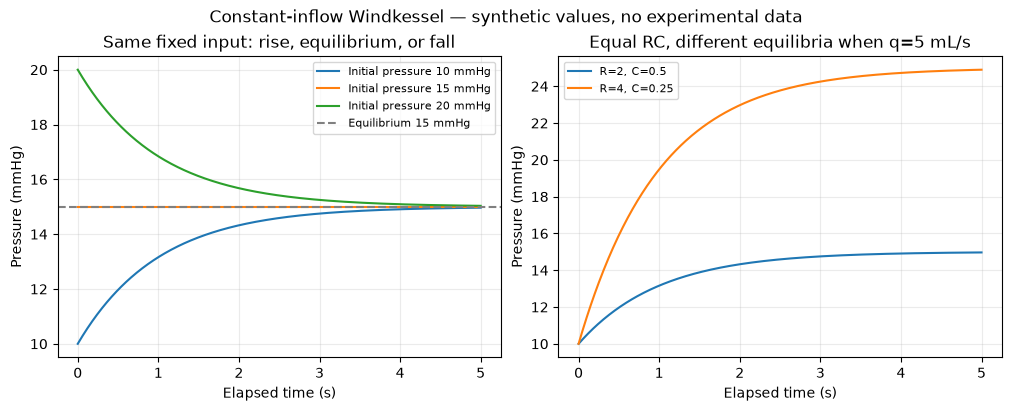

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
for initial in (10.0, p_star, 20.0):
    axes[0].plot(times, [constant_pressure(t, initial) for t in times],
                 label=f"Initial pressure {initial:g} mmHg")
axes[0].axhline(p_star, linestyle="--", color="gray", label="Equilibrium 15 mmHg")
axes[0].set_title("Same fixed input: rise, equilibrium, or fall")
for resistance, compliance in ((R, C), (other_R, other_C)):
    axes[1].plot(times, [constant_pressure(t, 10.0, resistance, compliance) for t in times],
                 label=f"R={resistance:g}, C={compliance:g}")
axes[1].set_title("Equal RC, different equilibria when q=5 mL/s")
for ax in axes:
    ax.set_xlabel("Elapsed time (s)")
    ax.set_ylabel("Pressure (mmHg)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.suptitle("Constant-inflow Windkessel — synthetic values, no experimental data")
repo_root = Path.cwd() if Path("CardioLean.lean").exists() else Path.cwd().parent
assert (repo_root / "CardioLean.lean").is_file()
output = repo_root / "docs/assets/windkessel-constant-inflow.png"
fig.savefig(output, dpi=160, metadata={"Software": "CardioLean constant-input notebook"})
plt.show()

## 4. Read the proof rather than trying to sample uniqueness

For two solutions p and g with the same input, let d=p−g. Subtracting their
balances gives `d'=-d/(RC)`. The integrating factor produces
`w(t)=d(t) exp(t/(RC))`, whose derivative is zero. The mean-value theorem makes
w constant on the interval. Equal initial pressures make that constant zero;
the strictly positive exponential then gives d=0.

The Lean theorem `solutions_unique` requires the ordinary derivative balance
at every point of [0,t], including endpoints. It is a conditional statement:
**if** both solutions satisfy those hypotheses, they agree at t. It does not
construct a solution for every possible input or cover discontinuous valve switching.
`constantPressure_unique` applies this argument to the explicit constant-input curve.

Questions for personal study:

- Why does the inflow cancel when subtracting two solutions?
- Why is checking an initial value alone insufficient?
- Which quantities does uniqueness hold fixed, and which does a parameter fit try to infer?
- What extra continuity and interface conditions would be needed when a valve changes state?
